In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
X = 6*np.random.rand(100,1) - 3
Y = 0.5*X**2 + X + 2 + np.random.randn(100,1)


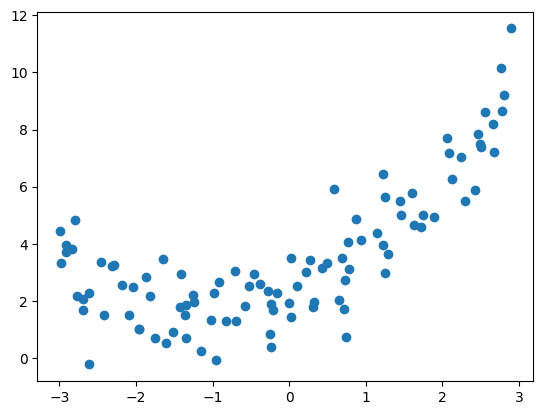

In [5]:
plt.scatter(X,Y)

In [33]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

NameError: name 'y' is not defined

In [14]:
## First Try ki Linear regression se kaisa result aayega 
## Lets implement Simple Linear Regression
from sklearn.linear_model import LinearRegression
regression_1=LinearRegression()

In [15]:
regression_1.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.96]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3.62]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[15.34]


In [16]:
from sklearn.metrics import r2_score
score=r2_score(y_test,regression_1.predict(X_test))
print(score)

0.45129600426647454


Text(0, 0.5, 'Y')

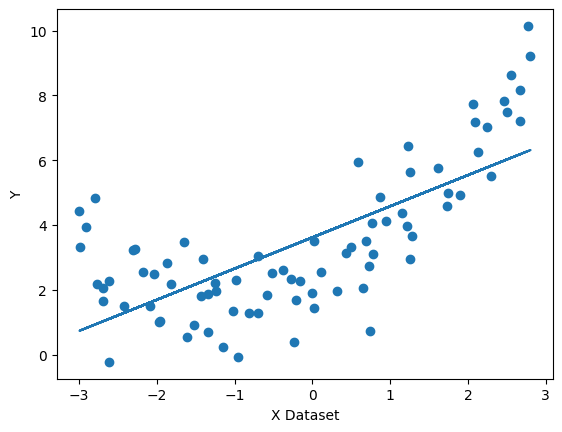

In [19]:
## Lets visualize this model
plt.plot(X_train,regression_1.predict(X_train))
plt.scatter(X_train,y_train)
plt.xlabel("X Dataset")
plt.ylabel("Y")


In [20]:
## now applying polynomial Transform 
from sklearn.preprocessing import PolynomialFeatures

In [22]:
poly=PolynomialFeatures(degree=2,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [23]:
X_train_poly

array([[ 1.00000000e+00, -2.76730347e+00,  7.65796850e+00],
       [ 1.00000000e+00, -2.69425426e+00,  7.25900601e+00],
       [ 1.00000000e+00,  7.33434086e-01,  5.37925559e-01],
       [ 1.00000000e+00, -8.19771888e-01,  6.72025948e-01],
       [ 1.00000000e+00, -1.51957408e+00,  2.30910539e+00],
       [ 1.00000000e+00,  2.06149709e+00,  4.24977023e+00],
       [ 1.00000000e+00,  8.72788145e-01,  7.61759147e-01],
       [ 1.00000000e+00,  6.87998345e-01,  4.73341723e-01],
       [ 1.00000000e+00, -2.91656816e+00,  8.50636982e+00],
       [ 1.00000000e+00,  1.25131916e+00,  1.56579964e+00],
       [ 1.00000000e+00, -9.60855232e-01,  9.23242777e-01],
       [ 1.00000000e+00,  9.43999865e-01,  8.91135745e-01],
       [ 1.00000000e+00, -1.64583836e+00,  2.70878390e+00],
       [ 1.00000000e+00, -2.08657078e+00,  4.35377760e+00],
       [ 1.00000000e+00, -5.22639704e-01,  2.73152260e-01],
       [ 1.00000000e+00, -2.60951864e+00,  6.80958755e+00],
       [ 1.00000000e+00,  7.62871933e-01

In [ ]:
from sklearn.metrics import r2_score
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.8591017686890668


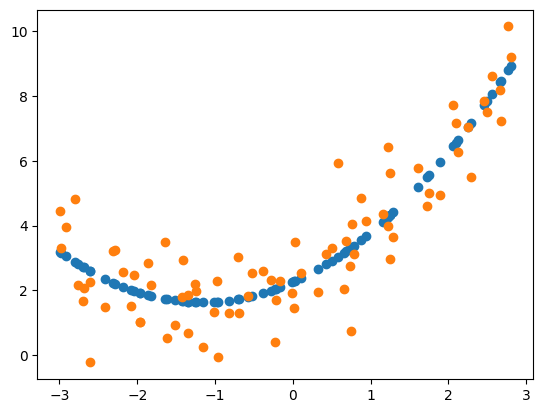

In [26]:
plt.scatter(X_train,regression.predict(X_train_poly))
plt.scatter(X_train,y_train)

In [29]:
from sklearn.preprocessing import PolynomialFeatures

In [30]:
poly2 = PolynomialFeatures(degree=3,include_bias=True)
X_test_cubic = poly2.fit_transform(X_test)
X_train_cubic = poly2.fit_transform(X_train)

In [32]:
from sklearn.linear_model import LinearRegression
regression = LinearRegression()
regression.fit(X_train_cubic, y_train)
y_pred = regression.predict(X_test_cubic)
score=r2_score(y_test,y_pred)
print(score)

0.85710831957275
